# Q5 : prédire l'annulation au moment de la réservation

**Question de la direction** : « Au moment de la réservation, on veut savoir si elle va être annulée. C'est ce qui décide du nombre de chambres qu'on peut revendre. »

**Auteure** : Kadidiatou Ibrahima Bagayoko

**Objectif** : obtenir, pour chaque réservation, une probabilité d'annulation fiable, réutilisée en question 6 pour fixer la surréservation.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/valmont_clean.csv")

# Les 6 réservations aberrantes sont exclues : elles fausseraient l'apprentissage
df = df[df["flag_anomalie"] == 0].copy()

print("Réservations :", df.shape)
print("Taux d'annulation :", round(df["a_annule"].mean(), 3))

# Un modèle qui répond toujours « honorée » a déjà cette justesse
print("Justesse d'un modèle naïf :", round(1 - df["a_annule"].mean(), 3))

Réservations : (794, 23)
Taux d'annulation : 0.261
Justesse d'un modèle naïf : 0.739


## 1. Les variables connues au moment de la réservation

Le modèle doit prédire une annulation au moment où le client réserve. Il ne peut donc utiliser que ce que l'hôtel sait à cet instant. Sont exclus :
- les identifiants (`reservation_id`, `hotel_id`) : ils ne décrivent rien, un modèle qui les utiliserait apprendrait par cœur ;
- `flag_anomalie` et `motif_anomalie` : ce sont des notes de nettoyage, pas des informations sur le client ;
- `mois_sejour` : il est remplacé par `saison`, plus robuste avec 794 réservations (12 modalités dispersent trop les données).

In [2]:
cible = "a_annule"

# Variables numériques : mesurées sur une échelle
var_num = ["delai_reservation_j", "nb_nuits", "nb_personnes", "prix_nuit_eur",
           "nuitees_cumulees_client", "weekend", "chambres", "salles_seminaire",
           "distance_gare_km", "nb_personnes_manquant", "petit_dejeuner_manquant"]

# Variables catégorielles : des modalités sans ordre
var_cat = ["canal", "segment_declare", "petit_dejeuner", "categorie", "saison"]

X = df[var_num + var_cat]
y = df[cible]

print("Variables retenues :", X.shape[1])
print("Valeurs manquantes :", X.isna().sum().sum())
print("Répartition de la cible :\n", y.value_counts())

Variables retenues : 16
Valeurs manquantes : 0
Répartition de la cible :
 a_annule
0    587
1    207
Name: count, dtype: int64


## 2. Quatre modèles du cours comparés à armes égales

On compare les quatre méthodes de classification vues en cours : régression logistique, k plus proches voisins, arbre de décision et forêt aléatoire.

Règles de la comparaison :
- **Validation croisée stratifiée à 5 plis** : chaque réservation sert une fois de test, et chaque pli garde 26 % d'annulations.
- **Préparation dans le pipeline** : la standardisation et l'encodage sont appris sur les plis d'entraînement seulement, pour qu'aucune information du test ne fuite.
- **Deux mesures** : l'AUC (capacité à classer une annulation au-dessus d'une réservation honorée, 0,5 = hasard) et le score de Brier (justesse des probabilités, indispensable pour la Q6 ; plus il est bas, mieux c'est).

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Standardisation des numériques (indispensable au kNN, qui mesure des distances)
# et encodage des catégorielles en colonnes 0/1
preparation = ColumnTransformer([
    ("num", StandardScaler(), var_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), var_cat),
])

# Réglages de départ raisonnables, affinés à l'étape suivante
modeles = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "kNN (k = 25)": KNeighborsClassifier(n_neighbors=25),
    "Arbre (profondeur 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lignes = []
for nom, modele in modeles.items():
    pipe = Pipeline([("prep", preparation), ("modele", modele)])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=["roc_auc", "neg_brier_score"])
    lignes.append({
        "Modèle": nom,
        "AUC moyenne": round(scores["test_roc_auc"].mean(), 3),
        "AUC écart-type": round(scores["test_roc_auc"].std(), 3),
        "Brier": round(-scores["test_neg_brier_score"].mean(), 3),
    })

comparaison = pd.DataFrame(lignes)

# Référence : un modèle qui prédit 26 % pour tout le monde
brier_naif = round(y.mean() * (1 - y.mean()), 3)
print("Brier du modèle naïf :", brier_naif)
comparaison

Brier du modèle naïf : 0.193


,Modèle,AUC moyenne,AUC écart-type,Brier
0,Régression logistique,0.609,0.048,0.188
1,kNN (k = 25),0.613,0.036,0.188
2,Arbre (profondeur 4),0.595,0.044,0.192
3,Forêt aléatoire,0.633,0.062,0.185


**Lecture des résultats**

- Les quatre modèles font mieux que le hasard (AUC de 0,5), mais de peu : l'AUC va de 0,60 à 0,63. Avec les informations disponibles au moment de la réservation, l'annulation reste difficile à prédire.
- Les écarts entre modèles (0,04 au plus) sont plus petits que leur variation d'un pli à l'autre (écart-type de 0,04 à 0,06). Aucun modèle ne domine nettement les autres.
- Le score de Brier (0,185 à 0,192) est à peine meilleur que celui du modèle naïf (0,193) : les probabilités apportent une information réelle mais modeste.

Question posée par ce résultat : seize variables n'apportent pas plus qu'un signal faible. Lesquelles portent vraiment l'information ? C'est l'objet de l'étape suivante.

## 3. Réglage du kNN et de l'arbre de décision

Deux réglages ont été fixés arbitrairement à l'étape précédente : le nombre de voisins k du kNN et la profondeur de l'arbre. On les choisit maintenant par validation croisée (mêmes 5 plis), en mesurant l'AUC pour plusieurs valeurs.

- **k petit** : le vote repose sur peu de voisins et suit le bruit. **k grand** : le vote lisse les cas particuliers.
- **Arbre peu profond** : quelques règles simples. **Arbre profond** : des règles très fines, qui risquent d'apprendre le bruit de l'échantillon (surapprentissage).

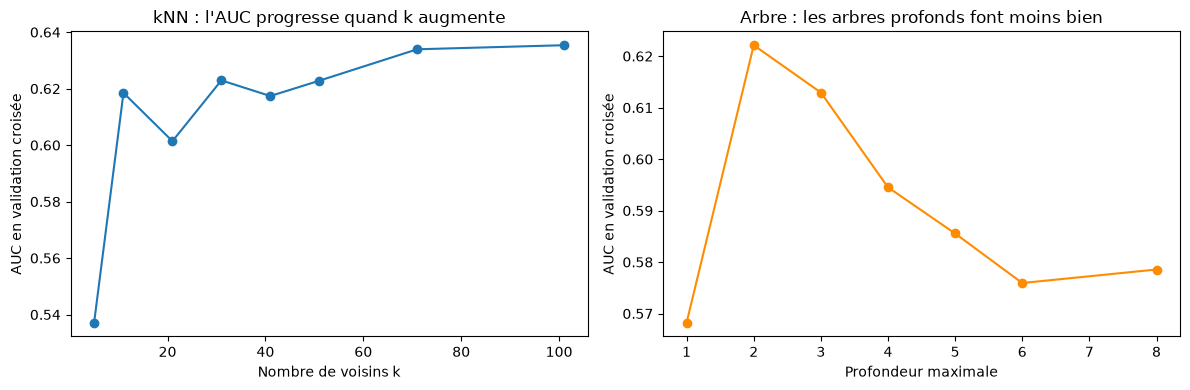

kNN : {5: 0.537, 11: 0.619, 21: 0.601, 31: 0.623, 41: 0.617, 51: 0.623, 71: 0.634, 101: 0.635}
Arbre : {1: 0.568, 2: 0.622, 3: 0.613, 4: 0.595, 5: 0.586, 6: 0.576, 8: 0.579}


In [5]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# AUC du kNN pour plusieurs nombres de voisins
valeurs_k = [5, 11, 21, 31, 41, 51, 71, 101]
auc_knn = []
for k in valeurs_k:
    pipe = Pipeline([("prep", preparation), ("modele", KNeighborsClassifier(n_neighbors=k))])
    auc_knn.append(cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc").mean())

# AUC de l'arbre pour plusieurs profondeurs
profondeurs = [1, 2, 3, 4, 5, 6, 8]
auc_arbre = []
for p in profondeurs:
    arbre = DecisionTreeClassifier(max_depth=p, min_samples_leaf=20, random_state=42)
    pipe = Pipeline([("prep", preparation), ("modele", arbre)])
    auc_arbre.append(cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc").mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(valeurs_k, auc_knn, marker="o")
axes[0].set_title("kNN : l'AUC progresse quand k augmente")
axes[0].set_xlabel("Nombre de voisins k")
axes[0].set_ylabel("AUC en validation croisée")

axes[1].plot(profondeurs, auc_arbre, marker="o", color="darkorange")
axes[1].set_title("Arbre : les arbres profonds font moins bien")
axes[1].set_xlabel("Profondeur maximale")
axes[1].set_ylabel("AUC en validation croisée")
plt.tight_layout()
plt.show()

print("kNN :", {k: round(float(a), 3) for k, a in zip(valeurs_k, auc_knn)})
print("Arbre :", {p: round(float(a), 3) for p, a in zip(profondeurs, auc_arbre)})

**Lecture des résultats**

- **kNN** : avec k = 5, l'AUC n'est que de 0,54, presque le hasard : 5 voisins votent sur du bruit. L'AUC monte avec k et se stabilise entre 0,62 et 0,635 au-delà de 30 voisins. Le modèle progresse quand il lisse les cas particuliers.
- **Arbre** : la meilleure profondeur est 2 (AUC de 0,622). Au-delà, l'AUC baisse jusqu'à 0,58 : un arbre profond apprend des règles propres à l'échantillon, qui ne se vérifient pas sur de nouvelles réservations. C'est du surapprentissage.

Les deux réglages mènent à la même conclusion : **plus le modèle est simple, mieux il prédit**. Le signal d'annulation est donc porté par peu de variables. L'étape suivante cherche lesquelles.

Réglages retenus : k = 71 pour le kNN (début du plateau) et une profondeur de 2 pour l'arbre.

## 4. Test de parcimonie : combien de variables faut-il vraiment ?

Les réglages précédents montrent que les modèles simples prédisent mieux. On le vérifie directement : on part de la seule variable du délai de réservation, signalé comme le facteur le plus fort par les questions 1 et 2, puis on ajoute des variables une à une. Si une variable n'améliore pas l'AUC en validation croisée, elle n'apporte que du bruit.

In [6]:
# Jeux de variables, du plus simple au plus complet
jeux = {
    "1. Délai seul": (["delai_reservation_j"], []),
    "2. Délai + segment": (["delai_reservation_j"], ["segment_declare"]),
    "3. Délai + segment + canal": (["delai_reservation_j"], ["segment_declare", "canal"]),
    "4. Les 16 variables": (var_num, var_cat),
}

lignes = []
for nom, (v_num, v_cat) in jeux.items():
    etapes = [("num", StandardScaler(), v_num)]
    if v_cat:
        etapes.append(("cat", OneHotEncoder(handle_unknown="ignore"), v_cat))
    pipe = Pipeline([("prep", ColumnTransformer(etapes)),
                     ("modele", LogisticRegression(max_iter=1000))])
    scores = cross_validate(pipe, df[v_num + v_cat], y, cv=cv,
                            scoring=["roc_auc", "neg_brier_score"])
    lignes.append({
        "Jeu de variables": nom,
        "Nombre de variables": len(v_num) + len(v_cat),
        "AUC moyenne": round(scores["test_roc_auc"].mean(), 3),
        "AUC écart-type": round(scores["test_roc_auc"].std(), 3),
        "Brier": round(-scores["test_neg_brier_score"].mean(), 3),
    })

parcimonie = pd.DataFrame(lignes)
parcimonie

,Jeu de variables,Nombre de variables,AUC moyenne,AUC écart-type,Brier
0,1. Délai seul,1,0.652,0.050,0.181
1,2. Délai + segment,2,0.649,0.053,0.181
2,3. Délai + segment + canal,3,0.643,0.053,0.182
3,4. Les 16 variables,16,0.609,0.048,0.188


**Lecture des résultats**

- **Le délai seul donne la meilleure prédiction** : AUC de 0,652 et Brier de 0,181. Il fait mieux que tous les modèles à 16 variables testés plus haut, forêt aléatoire comprise (0,633).
- **Ajouter le segment n'apporte rien** (0,649) : son information est déjà contenue dans le délai, car les clients affaires réservent tard et annulent peu.
- **Ajouter le canal fait légèrement baisser le score** (0,643) : le canal ne porte pas d'information propre sur l'annulation. Cela rejoint la question 1 : accuser les plateformes n'est pas justifié par les données.
- **Les 16 variables font nettement moins bien** (0,609) : chaque variable inutile ajoute du bruit que le modèle apprend à tort.

Les écarts entre les trois premiers jeux restent inférieurs à leur variation d'un pli à l'autre (écart-type de 0,05). À performance égale, on retient le modèle le plus simple : il est plus robuste sur de nouvelles réservations, et il s'explique en une phrase à la direction.

**Modèle retenu : régression logistique sur le délai de réservation.**

Limite assumée : une AUC de 0,65 reste modeste. Le modèle ne prédit pas chaque annulation individuellement. Il sert à estimer un risque moyen par groupe de réservations, et c'est exactement ce dont la question 6 a besoin pour fixer la surréservation.